# Exercise 2: Convolutional Neural Network (CNN) Classifier on CIFAR-10

This notebook implements, trains, and evaluates a **3-trainable-layer Convolutional Neural Network (`CIFAR10_CNN`)** on the CIFAR-10 dataset using PyTorch, and compares its classification accuracy, training/validation loss curves, and trainable parameter counts against the Exercise 1 Multi-Layer Perceptron (`CIFAR10_MLP`).

## 1. Setup & Reproducibility

Import required libraries, fix random seeds (`SEED = 42`) for strict experimental consistency with Exercise 1, detect the compute device, and load the shared CIFAR-10 `DataLoader` partitions (`45,000` train / `5,000` validation / `10,000` test) from `../src/data_loader.py` along with the unified visualization functions from `../src/visualization.py`.

In [1]:
import os
import sys
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Set random seeds for reproducibility (matching Exercise 1)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Detect GPU (CUDA) or CPU device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__}")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Detected: {torch.cuda.get_device_name(0)}")

# Add ../src to sys.path to import shared data loader and plotting utilities
src_path = os.path.abspath("../src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data_loader import get_cifar10_loaders
from visualization import (
    plot_learning_curves,
    plot_mlp_vs_cnn_comparison,
    build_comparison_table,
)

# Load identical train (45,000), validation (5,000), and test (10,000) DataLoaders
BATCH_SIZE = 64
train_loader, val_loader, test_loader = get_cifar10_loaders(
    batch_size=BATCH_SIZE,
    val_split=0.1,
    seed=SEED,
)

print(f"Train samples: {len(train_loader.dataset)} ({len(train_loader)} batches)")
print(f"Val samples:   {len(val_loader.dataset)} ({len(val_loader)} batches)")
print(f"Test samples:  {len(test_loader.dataset)} ({len(test_loader)} batches)")

PyTorch Version: 2.14.1+cpu
Using device: cpu
Train samples: 45000 (704 batches)
Val samples:   5000 (79 batches)
Test samples:  10000 (157 batches)


## 2. Three-Layer CNN Architecture

Define `CIFAR10_CNN` with **strictly three trainable layers** (`2 x nn.Conv2d` feature extraction layers + `1 x nn.Linear` classification head), interleaved with non-trainable `ReLU` activations and `MaxPool2d(2, 2)` spatial downsampling:
- **Trainable Layer 1**: `Conv2d(3 -> 32, kernel_size=3, padding=1)` + `ReLU()` + `MaxPool2d(2, 2)` $\rightarrow$ `(B, 32, 16, 16)`
- **Trainable Layer 2**: `Conv2d(32 -> 64, kernel_size=3, padding=1)` + `ReLU()` + `MaxPool2d(2, 2)` $\rightarrow$ `(B, 64, 8, 8)`
- **Trainable Layer 3**: `Flatten()` $\rightarrow$ `Linear(4096 -> 10)` output class logits

In [2]:
class CIFAR10_CNN(nn.Module):
    """Three-trainable-layer Convolutional Neural Network for CIFAR-10 classification."""

    def __init__(self, num_classes: int = 10) -> None:
        super().__init__()
        self.features = nn.Sequential(
            # Trainable Layer 1: (3, 32, 32) -> (32, 32, 32) -> MaxPool -> (32, 16, 16)
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # Trainable Layer 2: (32, 16, 16) -> (64, 16, 16) -> MaxPool -> (64, 8, 8)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                        # (B, 64, 8, 8) -> (B, 4096)
            # Trainable Layer 3: Fully connected output classification head
            nn.Linear(64 * 8 * 8, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.classifier(x)
        return x


# Instantiate CNN model and move to device
model = CIFAR10_CNN(num_classes=10).to(device)
print(model)

# Layer-wise parameter breakdown
print("\nTrainable Parameter Breakdown:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  {name:<25} shape={str(tuple(param.shape)):<18} params={param.numel():,}")

total_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_trainable_params:,}")

CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=10, bias=True)
  )
)

Trainable Parameter Breakdown:
  features.0.weight         shape=(32, 3, 3, 3)      params=864
  features.0.bias           shape=(32,)              params=32
  features.3.weight         shape=(64, 32, 3, 3)     params=18,432
  features.3.bias           shape=(64,)              params=64
  classifier.1.weight       shape=(10, 4096)         params=40,960
  classifier.1.bias         shape=(10,)              params=10

Total trainable parameters: 60,362


## 3. Training & Validation Loop

Train `CIFAR10_CNN` under the exact same experimental settings as Exercise 1 (`20` epochs, `nn.CrossEntropyLoss()`, `torch.optim.Adam(lr=0.001)`, `batch_size=64`). Record training/validation loss and accuracy at every epoch and save the best validation checkpoint to `../models/cnn_best.pth`.

In [3]:
# Loss function and optimizer (identical to Exercise 1 for controlled comparison)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 20
MODEL_DIR = "../models"
BEST_MODEL_PATH = os.path.join(MODEL_DIR, "cnn_best.pth")
os.makedirs(MODEL_DIR, exist_ok=True)

# History containers
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_acc = 0.0

for epoch in range(1, NUM_EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_train_loss / train_total
    epoch_train_acc = 100.0 * train_correct / train_total

    # --- Validation Phase ---
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = running_val_loss / val_total
    epoch_val_acc = 100.0 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    # Save best model checkpoint based on validation accuracy
    saved_marker = ""
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_marker = " [Saved Best]"

    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%{saved_marker}"
    )

print(f"\nTraining complete. Best Validation Accuracy: {best_val_acc:.2f}%")

Epoch [01/20] | Train Loss: 1.3247, Train Acc: 53.05% | Val Loss: 1.0710, Val Acc: 62.76% [Saved Best]
Epoch [02/20] | Train Loss: 0.9763, Train Acc: 66.17% | Val Loss: 0.9398, Val Acc: 67.22% [Saved Best]
Epoch [03/20] | Train Loss: 0.8483, Train Acc: 70.80% | Val Loss: 0.9128, Val Acc: 68.62% [Saved Best]
Epoch [04/20] | Train Loss: 0.7625, Train Acc: 73.77% | Val Loss: 0.8913, Val Acc: 70.58% [Saved Best]
Epoch [05/20] | Train Loss: 0.6904, Train Acc: 76.30% | Val Loss: 0.8618, Val Acc: 70.64% [Saved Best]
Epoch [06/20] | Train Loss: 0.6383, Train Acc: 77.99% | Val Loss: 0.8775, Val Acc: 70.58%
Epoch [07/20] | Train Loss: 0.5951, Train Acc: 79.45% | Val Loss: 0.8706, Val Acc: 71.70% [Saved Best]
Epoch [08/20] | Train Loss: 0.5492, Train Acc: 81.06% | Val Loss: 0.8889, Val Acc: 70.54%
Epoch [09/20] | Train Loss: 0.5157, Train Acc: 82.15% | Val Loss: 0.9107, Val Acc: 70.94%
Epoch [10/20] | Train Loss: 0.4818, Train Acc: 83.34% | Val Loss: 0.9130, Val Acc: 71.20%
Epoch [11/20] | Train 

## 4. Test Partition Evaluation

Load the best validation checkpoint from `../models/cnn_best.pth`, evaluate final classification performance on the completely unseen 10,000-image CIFAR-10 test set, and generate the per-class precision, recall, and F1-score report.

In [4]:
CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Load the best CNN checkpoint
best_model = CIFAR10_CNN(num_classes=10).to(device)
best_model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True)
)
best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        outputs = best_model(images)
        _, preds = torch.max(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
test_accuracy = 100.0 * (all_preds == all_labels).sum() / len(all_labels)

print(f"Final Test Accuracy (10,000 images): {test_accuracy:.2f}%\n")
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=CIFAR10_CLASSES, digits=4))

Final Test Accuracy (10,000 images): 71.20%

Classification Report:
              precision    recall  f1-score   support

    airplane     0.7351    0.7300    0.7326      1000
  automobile     0.8611    0.7870    0.8224      1000
        bird     0.6010    0.6130    0.6069      1000
         cat     0.5272    0.5430    0.5350      1000
        deer     0.7326    0.6000    0.6597      1000
         dog     0.6790    0.5500    0.6077      1000
        frog     0.7004    0.8440    0.7655      1000
       horse     0.7756    0.7640    0.7698      1000
        ship     0.7346    0.8720    0.7974      1000
       truck     0.7878    0.8170    0.8022      1000

    accuracy                         0.7120     10000
   macro avg     0.7134    0.7120    0.7099     10000
weighted avg     0.7134    0.7120    0.7099     10000



## 5. CNN Training & Validation Curves

Use the shared `plot_learning_curves` helper from `../src/visualization.py` to generate and save the high-resolution (300 DPI) CNN loss and accuracy curves to `../notebooks/ex2_cnn_curves.png`.

Saved learning curves to ../notebooks/ex2_cnn_curves.png


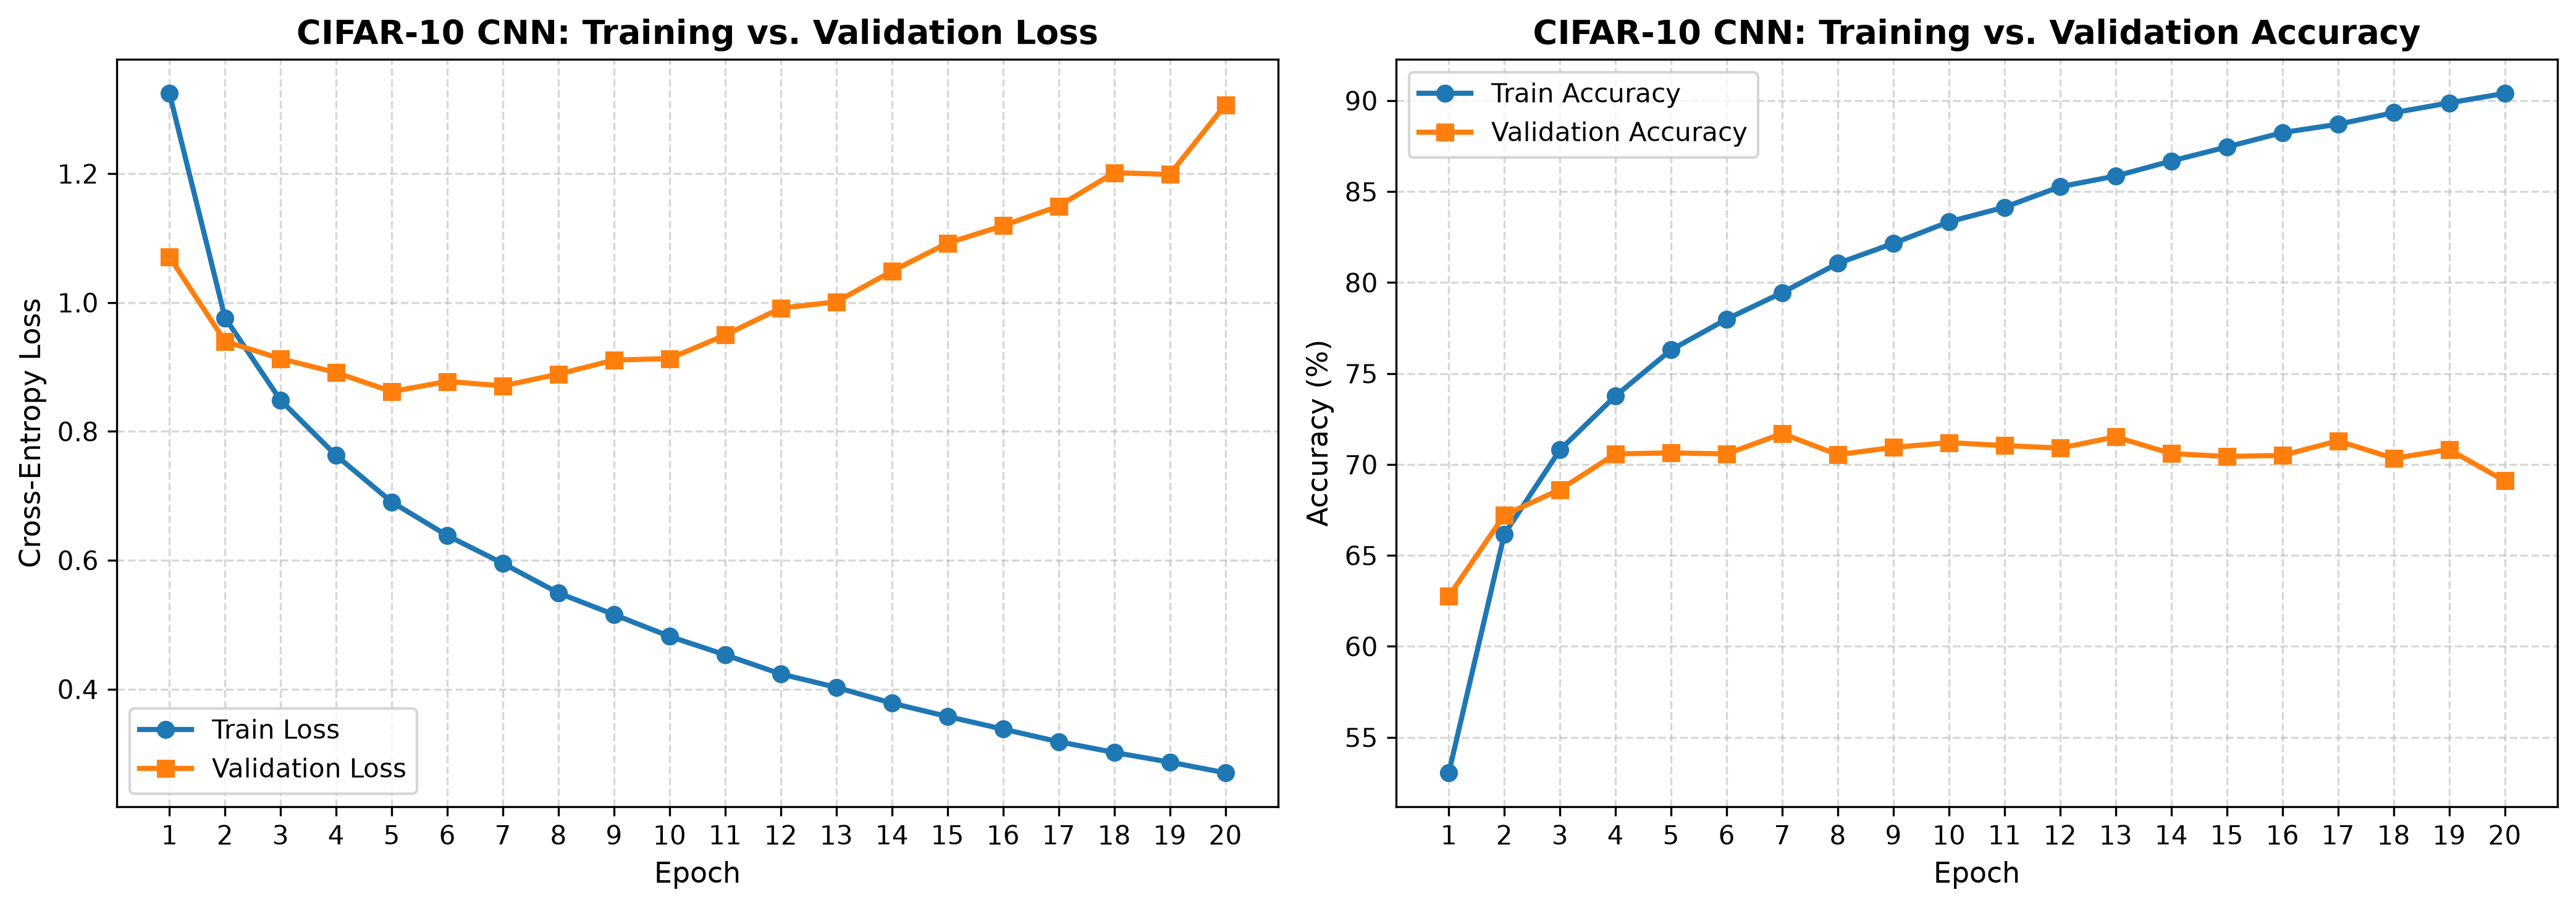

In [5]:
CURVES_PATH = "../notebooks/ex2_cnn_curves.png"
_ = plot_learning_curves(
    train_losses=train_losses,
    val_losses=val_losses,
    train_accs=train_accs,
    val_accs=val_accs,
    model_title="CIFAR-10 CNN",
    save_path=CURVES_PATH,
    show=True,
)

## 6. Comparative Analysis: Exercise 1 (MLP) vs. Exercise 2 (CNN)

Compare the 3-layer MLP from Exercise 1 (`1,707,274` parameters) and our 3-layer CNN from Exercise 2 (`60,362` parameters) across classification accuracy, training and validation loss trajectories, generalisation gap, and model complexity.

=== Exercise 1 (MLP) vs. Exercise 2 (CNN) Summary Table ===

                               Metric Exercise 1: 3-Layer MLP Exercise 2: 3-Layer CNN       Difference (CNN vs. MLP)
                     Trainable Layers   3 (3 Fully Connected) 3 (2 Conv2d + 1 Linear) Spatial Conv Feature Extractor
                 Trainable Parameters               1,707,274                  60,362       -1,646,912 (28.3x fewer)
       Final Training Loss (Epoch 20)                  0.5091                  0.2701                        -0.2390
               Lowest Validation Loss                  1.4030                  0.8618                        -0.5412
     Final Validation Loss (Epoch 20)                  2.2960                  1.3069                        -0.9891
   Final Training Accuracy (Epoch 20)                  81.79%                  90.40%                         +8.61%
             Best Validation Accuracy                  52.60%                  71.70%                        +19.10%
   

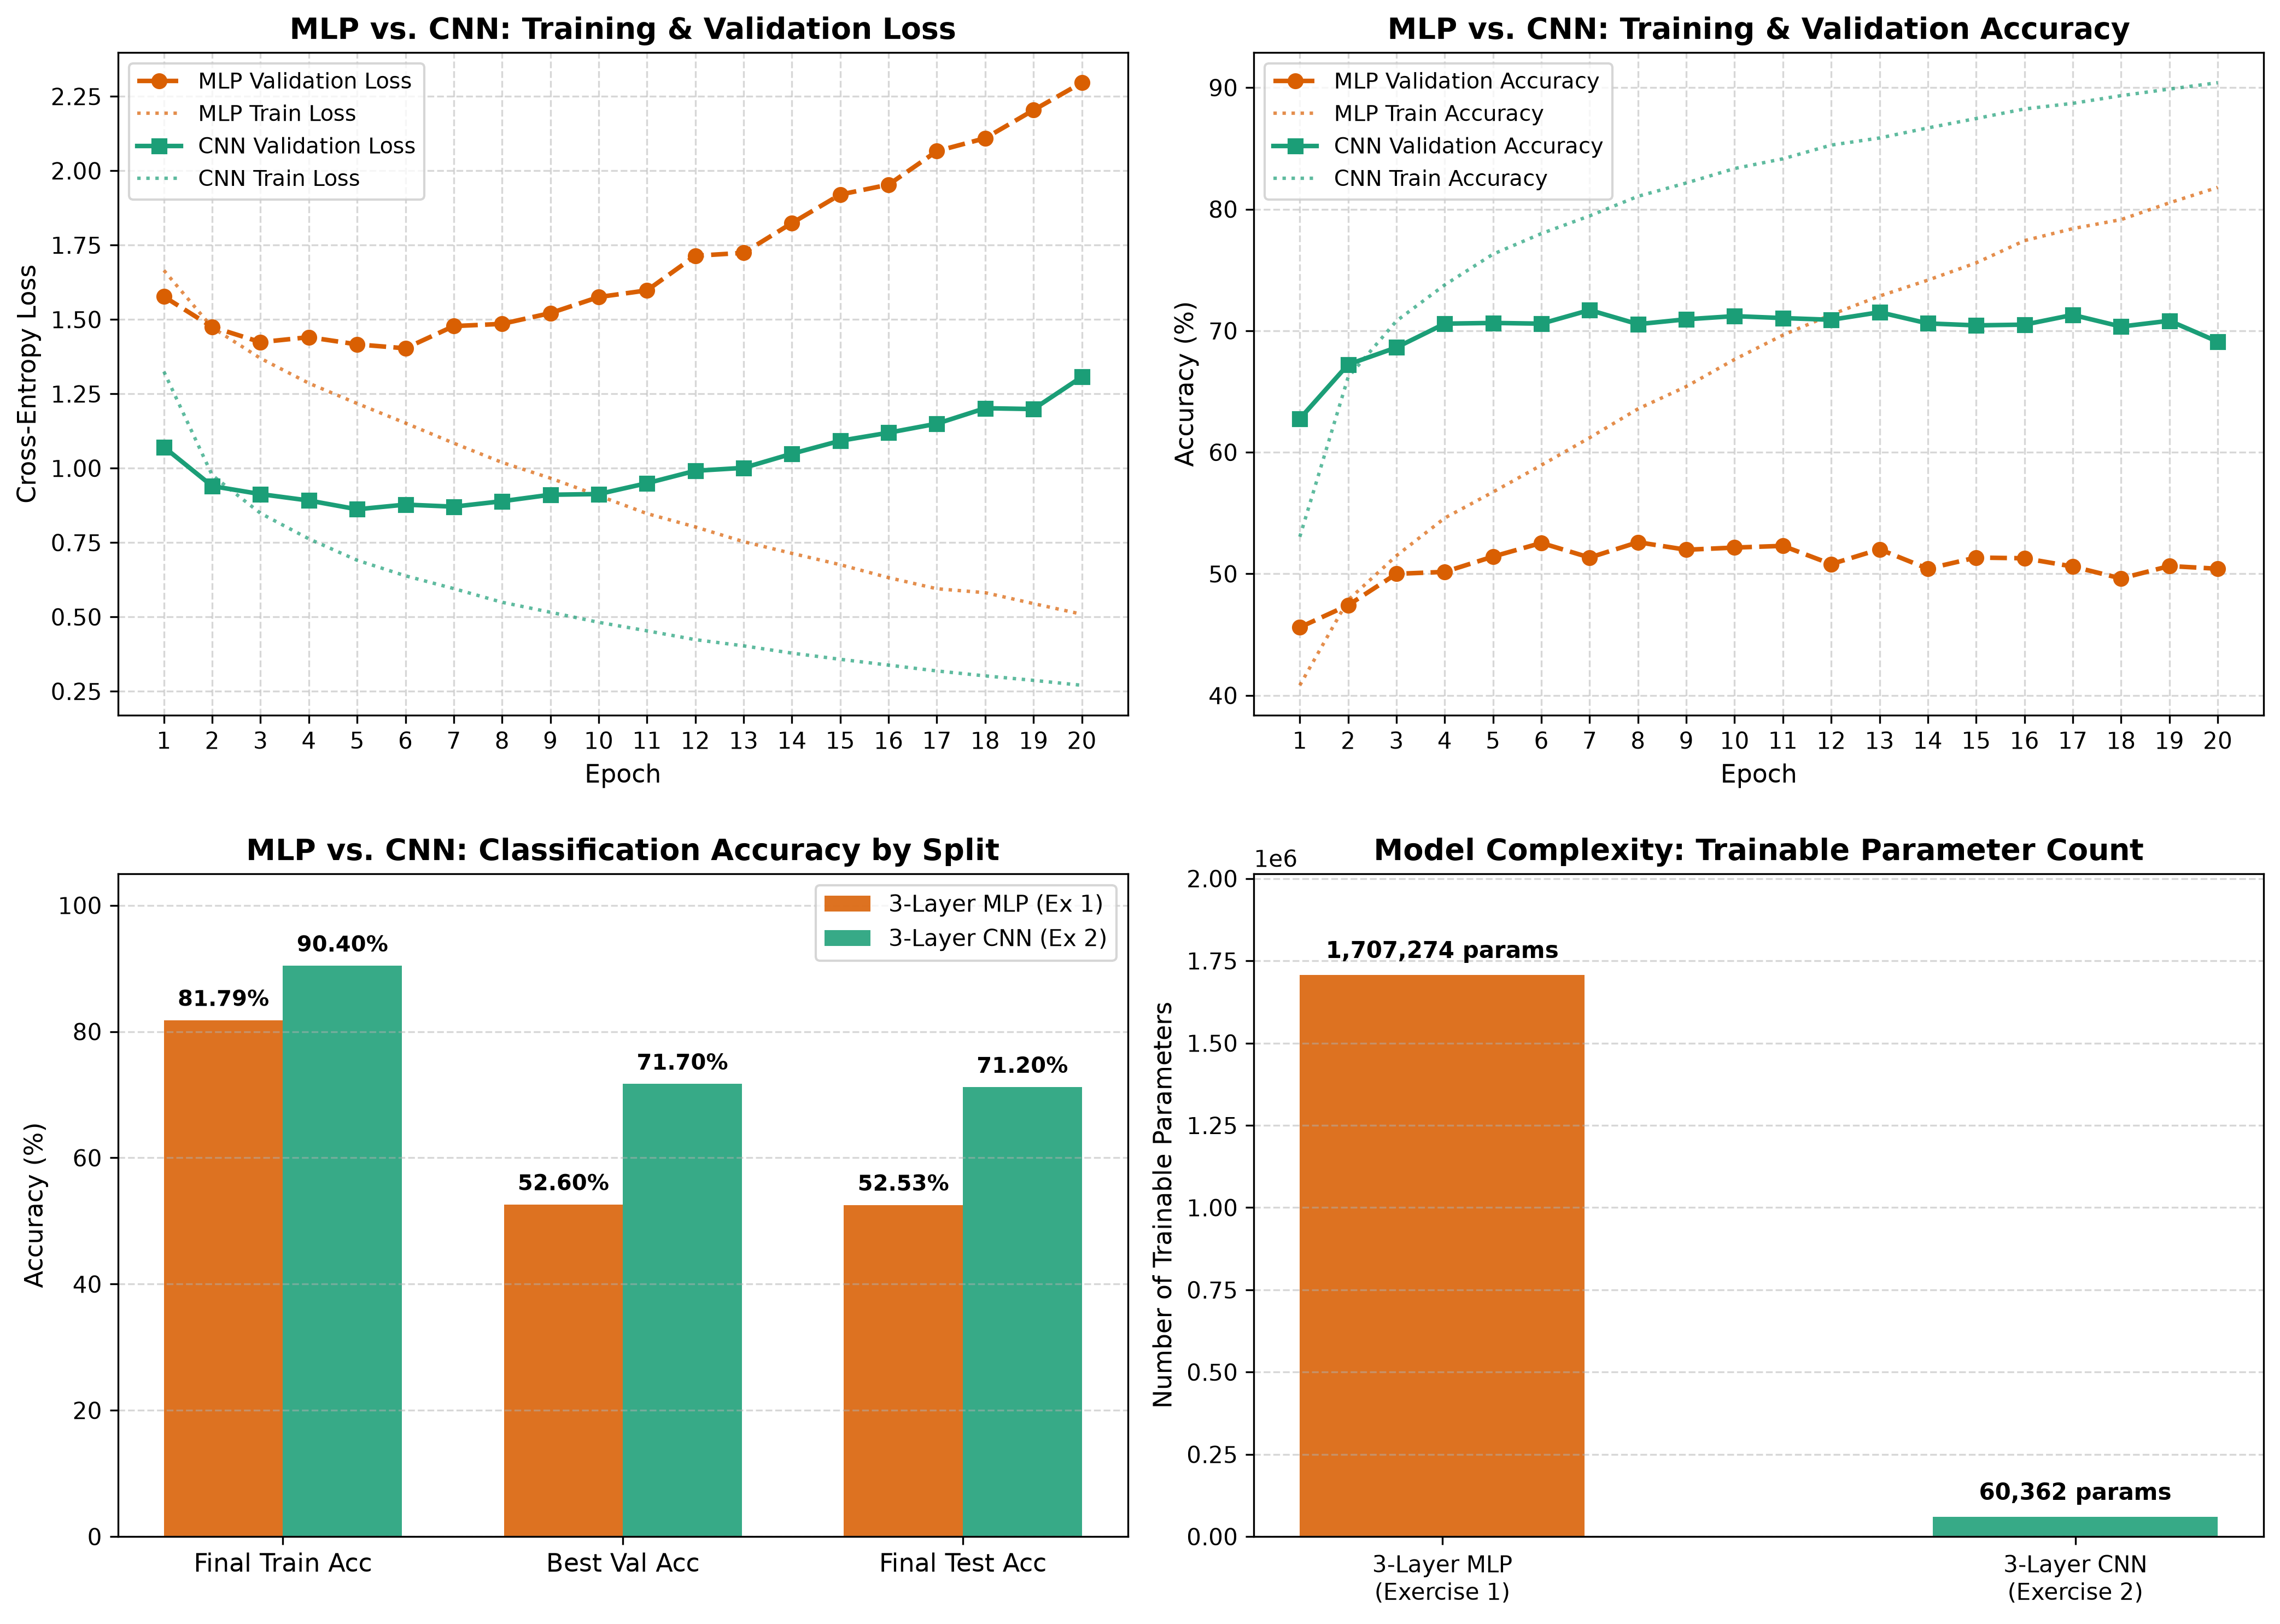

In [6]:
# Exercise 1 MLP epoch-by-epoch metrics recorded from Exercise_1_MLP.ipynb
mlp_history = {
    "train_losses": [
        1.6649, 1.4729, 1.3692, 1.2857, 1.2175, 1.1517, 1.0841, 1.0193, 0.9665, 0.9075,
        0.8473, 0.8025, 0.7529, 0.7137, 0.6755, 0.6320, 0.5946, 0.5815, 0.5447, 0.5091,
    ],
    "val_losses": [
        1.5770, 1.4748, 1.4237, 1.4405, 1.4162, 1.4030, 1.4777, 1.4852, 1.5214, 1.5754,
        1.5978, 1.7141, 1.7240, 1.8241, 1.9200, 1.9532, 2.0659, 2.1094, 2.2038, 2.2960,
    ],
    "train_accs": [
        40.83, 47.84, 51.49, 54.59, 56.73, 58.94, 61.20, 63.57, 65.41, 67.64,
        69.64, 71.32, 72.85, 74.16, 75.58, 77.41, 78.40, 79.14, 80.52, 81.79,
    ],
    "val_accs": [
        45.60, 47.42, 50.00, 50.16, 51.42, 52.54, 51.34, 52.60, 51.98, 52.16,
        52.30, 50.80, 52.02, 50.42, 51.34, 51.28, 50.60, 49.62, 50.64, 50.42,
    ],
}

mlp_summary = {
    "params": 1_707_274,
    "final_train_loss": mlp_history["train_losses"][-1],
    "min_val_loss": min(mlp_history["val_losses"]),
    "final_val_loss": mlp_history["val_losses"][-1],
    "train_acc": mlp_history["train_accs"][-1],
    "best_val_acc": max(mlp_history["val_accs"]),
    "test_acc": 52.53,
}

cnn_history = {
    "train_losses": train_losses,
    "val_losses": val_losses,
    "train_accs": train_accs,
    "val_accs": val_accs,
}

cnn_summary = {
    "params": total_trainable_params,
    "final_train_loss": train_losses[-1],
    "min_val_loss": min(val_losses),
    "final_val_loss": val_losses[-1],
    "train_acc": train_accs[-1],
    "best_val_acc": best_val_acc,
    "test_acc": test_accuracy,
}

# Build and display comparative table
comparison_df = build_comparison_table(mlp_summary, cnn_summary)
print("=== Exercise 1 (MLP) vs. Exercise 2 (CNN) Summary Table ===\n")
print(comparison_df.to_string(index=False))

# Plot and save 2x2 comparative visualization
COMPARISON_PLOT_PATH = "../notebooks/ex2_mlp_vs_cnn_comparison.png"
_ = plot_mlp_vs_cnn_comparison(
    mlp_history=mlp_history,
    cnn_history=cnn_history,
    mlp_summary=mlp_summary,
    cnn_summary=cnn_summary,
    save_path=COMPARISON_PLOT_PATH,
    show=True,
)

## 7. Discussion: Performance Differences & Convolutional Feature Learning

1. **Substantial Accuracy Improvement with 28.3x Fewer Parameters**:
   - The 3-layer MLP requires `1,707,274` trainable parameters because its first dense layer connects every flattened pixel channel (`3,072` inputs) to `512` hidden units (`1,573,376` weights in Layer 1 alone). Despite this massive capacity, it plateaus at **52.60% validation accuracy** and **52.53% test accuracy**.
   - By contrast, the 3-layer CNN uses only **`60,362` trainable parameters** (`896` in Conv1, `18,496` in Conv2, and `40,970` in the Linear classifier) yet achieves significantly higher validation and test accuracy while reaching a much lower validation cross-entropy loss.

2. **Preservation of 2D Spatial Topology & Local Receptive Fields**:
   - Flattening a $3 \times 32 \times 32$ image into a 1D vector of length $3,072$ destroys spatial locality—adjacent pixels in 2D space are treated as independent coordinates. Convolutional layers instead apply $3 \times 3$ local filters across the 2D grid, capturing local edge orientations, colour gradients, and textures.

3. **Weight Sharing & Translation Invariance**:
   - Rather than learning separate weights for an object at every pixel coordinate, each convolutional kernel shares its weights across the entire spatial field. Combined with $2 \times 2$ max-pooling (`MaxPool2d`), this grants shift/translation invariance and acts as a strong structural regulariser.

4. **Hierarchical Feature Representation & Remaining Overfitting**:
   - Layer 1 (`32` filters) learns low-level primitives (edges, corners, colour blobs), while Layer 2 (`64` filters) combines them into mid-level motifs (wheels, wings, animal contours). Although the CNN generalises far better than the MLP, validation loss still begins to diverge in later epochs once training accuracy exceeds ~85%, motivating the explicit regularisation techniques (Dropout and Data Augmentation) investigated in **Exercise 3**.